# Singtel – Churn risk for the 20% outreach list

**Question.** Which customers should the retention team call this quarter, given capacity for about 20% of the base, and do contact-centre transcripts improve that list?

**Answers*

1. Calling the top 20% by model score reaches **53% of churners at 70% precision, 2.6× a random list** - This is basedon test set
2. Churn sits in month-to-month fibre customers in their first year. **98.6% of the 20% list is month-to-month** and 83% is fibre.
3. Among callers: caller-churners on the list rise from **37 to 48 of 65**.

In [18]:
import sys, os, warnings
ROOT = os.path.abspath("..")
sys.path.insert(0, ROOT)
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Same functions the pipeline runs (make run): extract -> make_dataset -> build_features -> train_model
from src.data.make_dataset import load_customers, load_calls, load_raw_calls, T0
from src.features.build_features import make_split
from src.features.tabular_features import build_tabular, tenure_band
from src.features.transcript_features import (prepare_call_text, sequence_features,
                                              out_of_fold_text_risk, TextRiskScorer)
from src.models.churn_model import (SEED, CAPACITY, at_capacity, evaluate, gain_curve, bootstrap_delta,
                                    bootstrap_ci, logistic_pipeline, lgbm_model, cross_validate, score_table)
from src.models.microsegments import assign_segments, segment_summary, REASON_GROUP
from src.visualization.visualize import style, save, churn_rate_bars, gains_plot, SINGTEL_RED, INK, GREY

style()
pd.set_option("display.width", 200, "display.max_columns", 30)
DECK = {}   # numbers reused by the ExCom deck, written to reports/deck_data.json at the end

## 0. Data and quality fixes

In [19]:
customers, cust_audit = load_customers()
ids = set(customers["CustomerID"])
print(f"{len(customers):,} customers, {customers.shape[1]} columns; churn rate {customers['churn'].mean():.1%}")
pd.DataFrame(cust_audit, columns=["Issue", "Rows", "Action"])

7,043 customers, 34 columns; churn rate 26.5%


,Issue,Rows,Action
0,"Blank Total Charges (all tenure 0, none churned)",11,Set to 0: no bill has been issued yet
1,Count has one value (1),7043,Dropped from features
2,Country has one value (United States),7043,Dropped from features
3,State has one value (California),7043,Dropped from features
4,Churn Score / CLTV are IBM model outputs built...,7043,Excluded from features; CLTV kept only as a va...
5,Churn Reason is recorded at exit (churners only),1869,Excluded from features; used only to read the ...


## 1. Exploratory data analysis

Bars are churn rates with the base size under each label; the dashed line is the 26.5% base rate. Red bars are at least 10% above it.

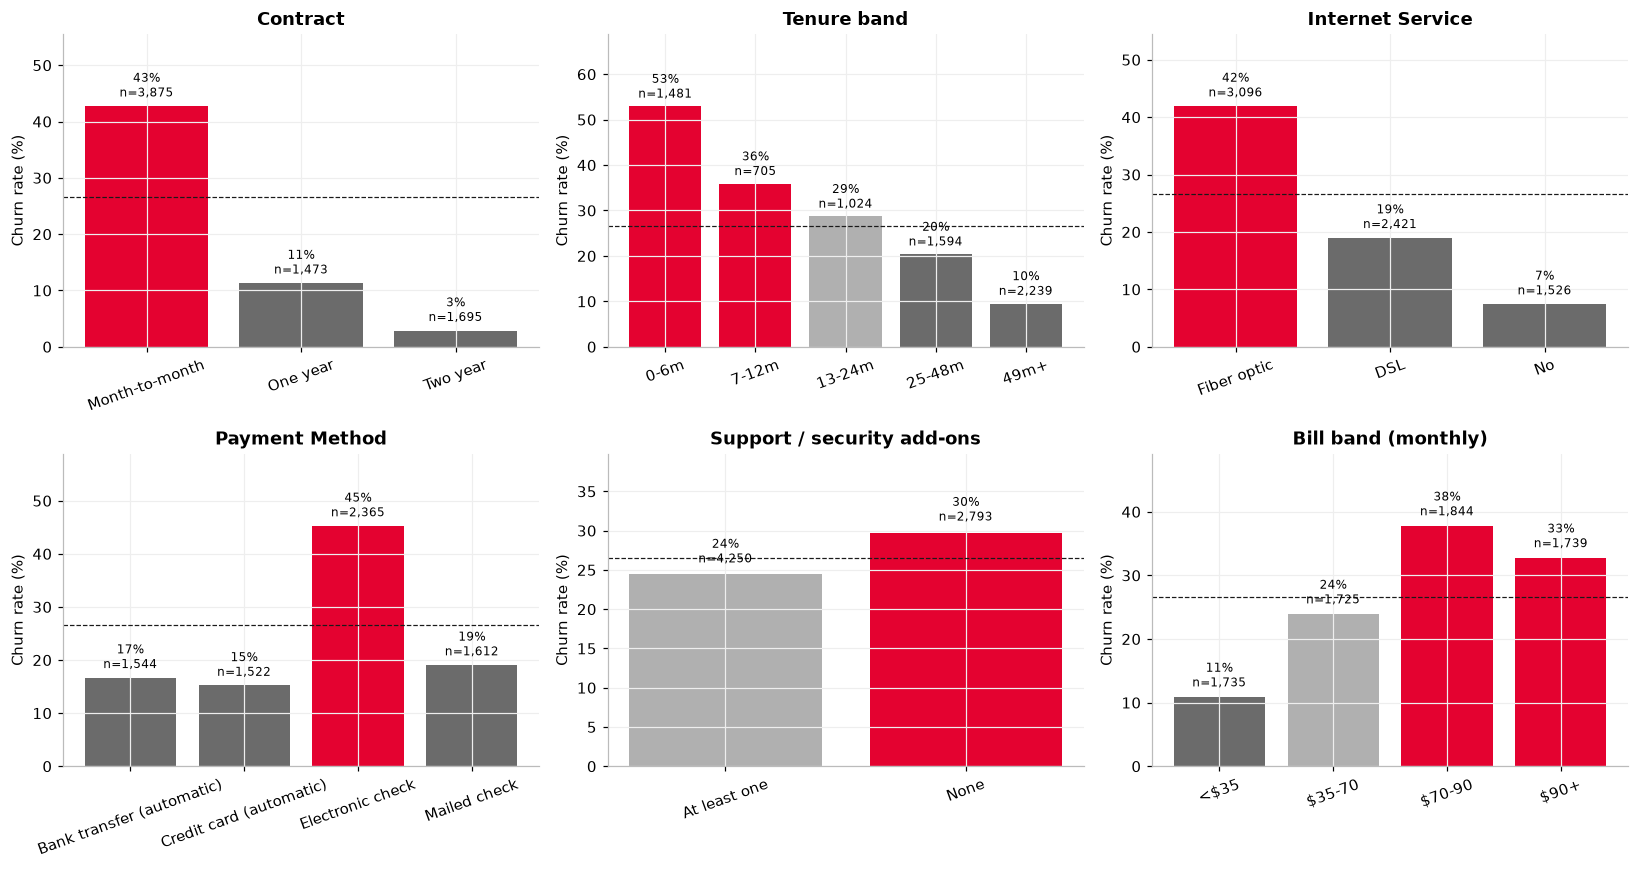

In [20]:
c = customers.copy()
X_all = build_tabular(customers)
c["Tenure band"] = tenure_band(c["Tenure Months"])
c["Support / security add-ons"] = np.where(X_all["protection_addons"].values > 0, "At least one", "None")
c["Bill band (monthly)"] = pd.cut(c["Monthly Charges"], [0, 35, 70, 90, 200], labels=["<$35", "$35-70", "$70-90", "$90+"])

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, (col, order) in zip(axes.ravel(), [
        ("Contract", ["Month-to-month", "One year", "Two year"]),
        ("Tenure band", None), ("Internet Service", ["Fiber optic", "DSL", "No"]),
        ("Payment Method", None), ("Support / security add-ons", None), ("Bill band (monthly)", None)]):
    churn_rate_bars(c, col, ax=ax, order=order)
fig.tight_layout(); save(fig, "eda_churn_drivers.png"); plt.show()

In [21]:
# Interactions that matter for targeting: contract x internet x tenure
pivot = (c.groupby(["Contract", "Internet Service", "Tenure band"], observed=True)["churn"]
           .agg(["size", "mean"]).query("size >= 50").sort_values("mean", ascending=False))
pivot.columns = ["customers", "churn_rate"]
pivot.head(10).style.format({"churn_rate": "{:.1%}", "customers": "{:,}"})

In [22]:
# Revenue view: churners are not low-value customers
summary = c.groupby("churn").agg(customers=("churn", "size"), avg_monthly_bill=("Monthly Charges", "mean"),
                                  median_tenure=("Tenure Months", "median"))
reasons = (c.loc[c.churn == 1, "Churn Reason"].map(REASON_GROUP).value_counts(normalize=True)
             .rename("share_of_churners"))
display(summary.round(1)); display(reasons.to_frame().style.format("{:.1%}"))
DECK["eda"] = {
    "base_customers": len(c), "churn_rate": c.churn.mean(), "churners": int(c.churn.sum()),
    "by_contract": c.groupby("Contract")["churn"].mean().to_dict(),
    "by_tenure": c.groupby("Tenure band", observed=True)["churn"].mean().to_dict(),
    "by_tenure_n": c.groupby("Tenure band", observed=True)["churn"].size().to_dict(),
    "by_internet": c.groupby("Internet Service")["churn"].mean().to_dict(),
    "by_payment": c.groupby("Payment Method")["churn"].mean().to_dict(),
    "by_protect": c.groupby("Support / security add-ons")["churn"].mean().to_dict(),
    "reason_mix": reasons.to_dict(),
    "avg_bill": summary["avg_monthly_bill"].to_dict(),
}

,customers,avg_monthly_bill,median_tenure
churn,,,
0,5174,61.3,38.0
1,1869,74.4,10.0


,share_of_churners
Churn Reason,
Competitor,33.2%
Product / network,22.8%
Support experience,19.6%
Price,13.0%
Unknown,8.2%
Not saveable,3.2%


**observations**

 **Contract is the dominant split.** Month-to-month churns 42.7%, one-year 11.3%, two-year 2.8%. 55% of customers are month-to-month.
 **Churn is front-loaded.** 52.9% of customers in their first 6 months churn, falling to 9.5% after 4 years. Median tenure is 10 months for churners and 38 for those who stay.
 **Fibre churns at twice the DSL rate** (41.9% vs 19.0%) at a higher bill. The combination matters more than either alone: month-to-month fibre in months 0-6 churns 74.2% (619 customers).
 **Electronic-check payers churn 45.3%**, against 15-19% for every other method. Likely a proxy for lower commitment (no auto-pay), not a cause.
  
 **Churners pay more:** $74 a month on average vs $61 for those who stay, so the list protects above-average revenue.
 **Recorded reasons:** competitor offers 33%, product/network 23%, support experience 20%, price 13%. Only 3% (moved, deceased) are outside the company's control.

## 2. Model development

**Split.** One stratified 75/25 split (seed 270), reused by every model in this notebook, including the transcript model. Hyper-parameter and design choices use 5-fold cross-validation on the training set only; the test set is scored once per model.

In [23]:
X = build_tabular(customers)
y = customers.set_index("CustomerID")["churn"]
train_ids, test_ids = make_split(customers)
X_tr, X_te, y_tr, y_te = X.loc[train_ids], X.loc[test_ids], y.loc[train_ids], y.loc[test_ids]
print(f"train {len(train_ids):,} ({y_tr.mean():.1%} churn) | test {len(test_ids):,} ({y_te.mean():.1%} churn)")
print(f"20% of the test set = {round(0.2*len(test_ids))} customers")

train 5,282 (26.5% churn) | test 1,761 (26.5% churn)
20% of the test set = 352 customers


### 2.1 Algorithm and class imbalance

regularised logistic regression (one-hot categoricals, scaled numerics) and LightGBM (handles interactions without manual crosses). Churn is 26.5%, so the imbalance is moderate. 

In [24]:
spw = (y_tr == 0).sum() / (y_tr == 1).sum()
candidates = {
    "Logistic, no weighting": lambda: logistic_pipeline(X_tr, class_weight=None),
    "Logistic, class-weighted": lambda: logistic_pipeline(X_tr, class_weight="balanced"),
    "LightGBM, no weighting": lambda: lgbm_model(None),
    "LightGBM, class-weighted": lambda: lgbm_model(spw),
}
cv_rows = {}
for name, make in candidates.items():
    _, folds = cross_validate(make, X_tr, y_tr)
    cv_rows[name] = folds.mean()
cv = pd.DataFrame(cv_rows).T[["recall@20", "precision@20", "lift@20", "pr_auc", "roc_auc", "accuracy@0.5"]]
cv.style.format("{:.3f}").highlight_max(color="#F4C7CF")

,recall@20,precision@20,lift@20,pr_auc,roc_auc,accuracy@0.5
"Logistic, no weighting",0.524,0.696,2.621,0.680,0.858,0.816
"Logistic, class-weighted",0.524,0.696,2.621,0.679,0.858,0.761
"LightGBM, no weighting",0.511,0.680,2.560,0.680,0.860,0.809
"LightGBM, class-weighted",0.512,0.681,2.564,0.683,0.860,0.764


**Choice:** Logistic regression without class-weights as it beats the lightgbm in top 20%

In [25]:
tab_model = logistic_pipeline(X_tr, class_weight="balanced").fit(X_tr, y_tr)
p_tab = tab_model.predict_proba(X_te)[:, 1]
challenger = lgbm_model(spw).fit(X_tr, y_tr)
p_lgb = challenger.predict_proba(X_te)[:, 1]

test_metrics = pd.DataFrame({"Logistic (chosen)": evaluate(y_te, p_tab),
                             "LightGBM (challenger)": evaluate(y_te, p_lgb)}).T
test_metrics[["accuracy@0.5", "recall@20", "precision@20", "lift@20", "churners_caught", "pr_auc", "roc_auc"]].style.format(
    {"accuracy@0.5": "{:.1%}", "recall@20": "{:.1%}", "precision@20": "{:.1%}", "lift@20": "{:.2f}x",
     "churners_caught": "{:.0f}", "pr_auc": "{:.3f}", "roc_auc": "{:.3f}"})

,accuracy@0.5,recall@20,precision@20,lift@20,churners_caught,pr_auc,roc_auc
Logistic (chosen),75.8%,52.7%,69.9%,2.64x,246,0.671,0.859
LightGBM (challenger),75.9%,50.5%,67.0%,2.53x,236,0.684,0.859


In [26]:
# What the logistic model has learned: largest effects on the odds of churn
pre = tab_model.named_steps["pre"]; lr = tab_model.named_steps["lr"]
coef = pd.Series(lr.coef_[0], index=pre.get_feature_names_out()).rename(lambda s: s.split("__", 1)[1])
effects = pd.DataFrame({"odds_multiplier": np.exp(coef)}).sort_values("odds_multiplier")
display(pd.concat([effects.tail(8)[::-1], effects.head(6)]).style.format("{:.2f}"))

,odds_multiplier
Contract_Month-to-month,2.04
Paperless Billing_Yes,1.46
new_customer,1.41
Monthly Charges,1.34
Partner_Yes,1.32
Internet Service_Fiber optic,1.30
Payment Method_Electronic check,1.27
Senior Citizen_Yes,1.14
Dependents_Yes,0.25
Contract_Two year,0.43


### 2.3 Does Total Charges make sense?

In [27]:
X_tc = build_tabular(customers, t0_safe=False)
p_tc = logistic_pipeline(X_tc.loc[train_ids]).fit(X_tc.loc[train_ids], y_tr).predict_proba(X_tc.loc[test_ids])[:, 1]
pd.DataFrame({"Chosen (no Total Charges)": at_capacity(y_te, p_tab),
              "Adding Total Charges, avg billed, bill rise": at_capacity(y_te, p_tc)}).T.round(3)

,precision@20,recall@20,lift@20,churners_caught,contacted
Chosen (no Total Charges),0.699,0.527,2.635,246.0,352.0
"Adding Total Charges, avg billed, bill rise",0.693,0.522,2.614,244.0,352.0


Dropping Total Charges and the two fields changes nothing in terms of recall , They are left out of the chosen model

### 2.4 Tenure measured after T0

In [28]:
# Tenure is as of each customer's last account update, not T0.
# Check: every stayer's tenure covers first call -> 30 Jun; churners' stops at the date they left.
END = pd.Timestamp("2026-06-30")
calls_raw = load_raw_calls().assign(cid=lambda d: d.customer_id.astype(str).str.strip().str.upper())
span = calls_raw.groupby("cid").interaction_date.agg(["min", "max"]).join(customers.set_index("CustomerID")[["Tenure Months", "churn"]], how="inner")
months = lambda a, b: (b - a).dt.days / 30.44
print("Callers whose tenure is shorter than first call -> 30 Jun:",
      span[span["Tenure Months"] + 0.5 < months(span["min"], pd.Series(END, index=span.index))].groupby("churn").size().to_dict())

# Rebuild tenure as at 31 Mar t. Uses the label
# otherwise a uniform draw over Apr-Jun.
rng = np.random.default_rng(SEED)
last_call = customers.CustomerID.map(calls_raw.groupby("cid").interaction_date.max())
offset = np.where(customers.churn == 0, (END - T0).days / 30.44, np.nan)
exit_known = (customers.churn == 1) & (last_call > T0)
offset = np.where(exit_known, ((last_call - T0).dt.days / 30.44).clip(0, 3), offset)
offset[np.isnan(offset)] = rng.uniform(0, 3, np.isnan(offset).sum())
tenure_t0 = customers["Tenure Months"] - offset
print(f"Exit date from a post-T0 call: {exit_known.sum()} of {customers.churn.sum()} churners; "
      f"joined after T0 (tenure at T0 < 0): {(tenure_t0 < 0).sum()} customers")

def score_with(frame, keep=None):
    Xs = build_tabular(frame)
    tr = [i for i in train_ids if keep is None or keep[i]]
    te = [i for i in test_ids if keep is None or keep[i]]
    p = logistic_pipeline(Xs.loc[tr]).fit(Xs.loc[tr], y.loc[tr]).predict_proba(Xs.loc[te])[:, 1]
    return p, y.loc[te]

rebuilt = customers.assign(**{"Tenure Months": np.maximum(tenure_t0, 0).round()})
in_base = pd.Series((tenure_t0 >= 0).values, index=customers.CustomerID)
X_no_tenure = X.drop(columns=["Tenure Months", "new_customer"])
p_rebuilt, _ = score_with(rebuilt)
variants = {
    "As delivered (last account update)": (p_tab, y_te),
    "Rebuilt to 31 Mar": (p_rebuilt, y_te),
    "Rebuilt, joiners after T0 removed": score_with(rebuilt, in_base),
    "Shifted -3 months for everyone": score_with(customers.assign(**{"Tenure Months": np.maximum(customers["Tenure Months"] - 3, 0)})),
    "No tenure at all": (logistic_pipeline(X_no_tenure.loc[train_ids]).fit(X_no_tenure.loc[train_ids], y_tr)
                         .predict_proba(X_no_tenure.loc[test_ids])[:, 1], y_te),
}
tenure_table = pd.DataFrame({k: {**evaluate(yy, pp), "test customers": len(yy)} for k, (pp, yy) in variants.items()}).T
leak = bootstrap_delta(y_te, p_tab, p_rebuilt, "recall@20")
print(f"Recall@20 change from rebuilding tenure: {leak['delta']:+.1%} (95% CI {leak['ci_low']:+.1%} to {leak['ci_high']:+.1%})")
DECK["tenure_t0"] = {"table": tenure_table.round(4).to_dict(orient="index"), "delta": {k: float(v) for k, v in leak.items()},
                     "joined_after_t0": int((tenure_t0 < 0).sum())}
tenure_table[["test customers", "recall@20", "precision@20", "lift@20", "roc_auc"]].style.format(
    {"test customers": "{:,.0f}", "recall@20": "{:.1%}", "precision@20": "{:.1%}", "lift@20": "{:.2f}x", "roc_auc": "{:.3f}"})

Callers whose tenure is shorter than first call -> 30 Jun: {1: 50}
Exit date from a post-T0 call: 295 of 1869 churners; joined after T0 (tenure at T0 < 0): 665 customers
Recall@20 change from rebuilding tenure: -1.7% (95% CI -3.1% to +0.0%)


,test customers,recall@20,precision@20,lift@20,roc_auc
As delivered (last account update),"1,761",52.7%,69.9%,2.64x,0.859
Rebuilt to 31 Mar,"1,761",51.0%,67.6%,2.55x,0.852
"Rebuilt, joiners after T0 removed","1,590",52.1%,63.8%,2.60x,0.856
Shifted -3 months for everyone,"1,761",53.1%,70.5%,2.66x,0.856
No tenure at all,"1,761",46.9%,62.2%,2.35x,0.838


## 3. Evaluation

Accuracy at a 0.5, The retention team will call the top 20% by score

**Recall@20%**: share of all churners that land on the call list (how much churn we can reach).
**Precision@20%**: share of the list that would have churned (how much of the call budget is spent on real risk).
**Lift@20%**: precision divided by the base rate (vs calling at random).

Recall and precision at 20% move together here

Top 20% = 352 customers; 246 of 467 churners (recall 52.7%, 95% CI 49.1%-56.0%); precision 69.9%; lift 2.64x; a random list would reach 93.


,capacity,churners_caught,contacted,recall,precision,extra churners per extra 1% of base
0,10%,137,176,29.3%,77.8%,nan
1,20%,246,352,52.7%,69.9%,10.9
2,30%,313,528,67.0%,59.3%,6.7
3,40%,375,704,80.3%,53.3%,6.2


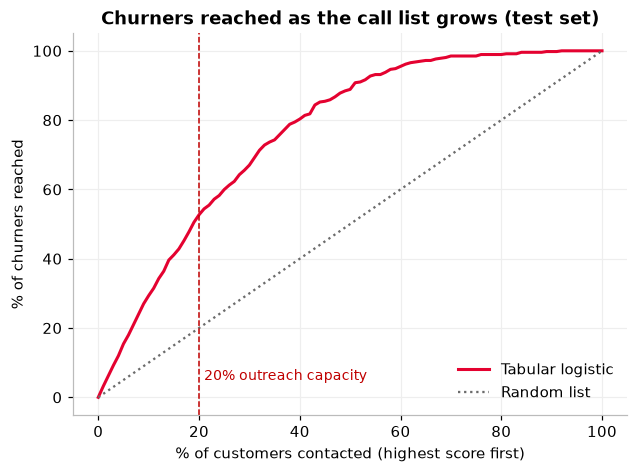

In [29]:
lo, hi = bootstrap_ci(y_te, p_tab, "recall@20")
m = at_capacity(y_te, p_tab)
print(f"Top 20% = {m['contacted']} customers; {m['churners_caught']} of {int(y_te.sum())} churners "
      f"(recall {m['recall@20']:.1%}, 95% CI {lo:.1%}-{hi:.1%}); precision {m['precision@20']:.1%}; "
      f"lift {m['lift@20']:.2f}x; a random list would reach {0.2*y_te.sum():.0f}.")

caps = pd.DataFrame([{"capacity": k, **{kk: v for kk, v in at_capacity(y_te, p_tab, k).items()
                                         if kk in ("contacted", "churners_caught")}} for k in (0.1, 0.2, 0.3, 0.4)])
caps["recall"] = caps.churners_caught / y_te.sum(); caps["precision"] = caps.churners_caught / caps.contacted
caps["extra churners per extra 1% of base"] = caps.churners_caught.diff() / (caps.capacity.diff() * 100)
display(caps.style.format({"capacity": "{:.0%}", "recall": "{:.1%}", "precision": "{:.1%}",
                           "extra churners per extra 1% of base": "{:.1f}"}))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
gains_plot({"Tabular logistic": gain_curve(y_te, p_tab)}, ax=ax)
ax.set_title("Churners reached as the call list grows (test set)")
save(fig, "gains_tabular.png"); plt.show()

In [30]:
#decile
dec = pd.DataFrame({"y": y_te.values, "p": p_tab})
dec["decile"] = pd.qcut(dec.p.rank(method="first", ascending=False), 10, labels=range(1, 11))
dec_tab = dec.groupby("decile", observed=True).agg(customers=("y", "size"), churn_rate=("y", "mean"), mean_score=("p", "mean"))
dec_tab["lift"] = dec_tab.churn_rate / y_te.mean()
dec_tab.style.format({"churn_rate": "{:.1%}", "mean_score": "{:.2f}", "lift": "{:.2f}x"})

,customers,churn_rate,mean_score,lift
decile,,,,
1,177,78.0%,0.91,2.94x
2,176,61.9%,0.81,2.34x
3,176,37.5%,0.71,1.41x
4,176,35.2%,0.58,1.33x
5,176,22.7%,0.45,0.86x
6,176,17.6%,0.30,0.66x
7,176,8.0%,0.18,0.30x
8,176,1.1%,0.10,0.04x
9,176,2.3%,0.05,0.09x


In [31]:
#Churn reasons
tbl_tab = score_table(customers, test_ids, p_tab, "churn_score")
ch = tbl_tab[tbl_tab.churn == 1].assign(reason_group=lambda d: d["Churn Reason"].map(REASON_GROUP))
reach = ch.groupby("reason_group").agg(churners=("rank", "size"), on_list=("in_top_20pct", "mean")).sort_values("churners", ascending=False)
reach.style.format({"on_list": "{:.0%}"})

,churners,on_list
reason_group,,
Competitor,164,55%
Product / network,114,54%
Support experience,98,55%
Price,42,52%
Unknown,36,42%
Not saveable,13,23%


**What this says**

- Accuracy is 75.8%, but a model that predicted "stays" for everyone would score 73.5%.
- **Recall@20 is 52.7% precision@20 69.9%, lift 2.64×.** Seven in ten calls go to customers who would otherwise leave.

### 3.1 Test-set: predicted churn score against recorded churn reason

In [32]:
os.makedirs(os.path.join(ROOT, "reports"), exist_ok=True)
tbl_tab.to_csv(os.path.join(ROOT, "reports", "test_scores_tabular.csv"), index=False)
with pd.option_context("display.max_rows", None, "display.max_colwidth", 45):
    print(tbl_tab[["rank", "CustomerID", "churn_score", "churn", "Churn Reason", "Contract",
                   "Tenure Months", "in_top_20pct"]].to_string(index=False, float_format=lambda v: f"{v:.3f}"))

 rank CustomerID  churn_score  churn                              Churn Reason       Contract  Tenure Months  in_top_20pct
    1 1400-MMYXY        0.969      1              Attitude of service provider Month-to-month              3          True
    2 3049-SOLAY        0.966      1 Competitor offered higher download speeds Month-to-month              3          True
    3 9300-AGZNL        0.964      1                   Product dissatisfaction Month-to-month              1          True
    4 9497-QCMMS        0.963      1              Competitor made better offer Month-to-month              1          True
    5 4826-XTSOH        0.962      1                Attitude of support person Month-to-month              1          True
    6 6108-OQZDQ        0.962      1              Attitude of service provider Month-to-month              4          True
    7 2725-KXXWT        0.961      1           Lack of self-service on Website Month-to-month              1          True
    8 8098-LLAZX

## 5. analysis: contact-centre transcripts
A call is usable only if the retention team could have seen it on that date.

In [33]:
raw_calls = load_raw_calls()
calls, set_aside, call_audit = load_calls(ids)
print(f"Raw extract: {len(raw_calls):,} calls, {raw_calls.customer_id.str.strip().str.upper().nunique():,} customer IDs")
display(pd.DataFrame(call_audit, columns=["Step", "Calls"]))
print(f"Usable: {len(calls):,} calls from {calls.customer_id.nunique():,} customers "
      f"({calls.customer_id.nunique()/len(customers):.1%} of the base); {calls.is_stub.sum()} of them have no usable text")

Raw extract: 2,353 calls, 908 customer IDs


,Step,Calls
0,customer_id had leading/trailing spaces (fixed...,47
1,Customer ID not in customer file (orphan),8
2,After scoring date T0 2026-03-31 (not observable),946
3,Duplicate log of the same call,17
4,"Empty or stub transcript ([call disconnected],...",38


Usable: 1,382 calls from 724 customers (10.3% of the base); 38 of them have no usable text


In [34]:
# cancellation calls can go: as the customer is already decided to churn or churned
post = raw_calls.assign(cid=raw_calls.customer_id.str.strip().str.upper())
post = post[post.interaction_date > T0].merge(customers[["CustomerID", "churn"]], left_on="cid", right_on="CustomerID")
term = post[post.call_type == "Termination Request"]
print(f"Post-T0 Termination Request calls: {len(term)}; resolved as 'Account Closed': {(term.resolution_status=='Account Closed').sum()}; "
      f"customer churned: {term.churn.mean():.0%}")
display(pd.crosstab(post.call_type, post.churn, normalize="index").rename(columns={0: "stayed", 1: "churned"})
          .sort_values("churned", ascending=False).head(5).style.format("{:.0%}"))

Post-T0 Termination Request calls: 266; resolved as 'Account Closed': 256; customer churned: 96%


churn,stayed,churned
call_type,,
Termination Request,4%,96%
Number Porting Enquiry,22%,78%
Retention Offer Discussion,31%,69%
Complaint / Escalation,60%,40%
Contract Enquiry,74%,26%


**This is the main leakage trap in the extract.** The workbook runs to 2026-06-30, three months past T0. After T0, 266 termination calls appear and 256 of them are closed as "Account Closed" on that same call: these are the cancellations themselves, recorded inside the outcome window. A model allowed to see them would look excellent and be useless on the scoring date. All 946 post-T0 calls are set aside; they are used only in section 5.3 to measure how early churners call.

In [35]:
# Bias checks on what remains (pre-T0 only)
pre = calls.merge(customers[["CustomerID", "churn"]], left_on="customer_id", right_on="CustomerID")
cust_rate = pre.drop_duplicates("customer_id").churn.mean()
print(f"Callers churn {cust_rate:.1%} vs {customers.churn.mean():.1%} for the base: calling is itself a signal.")
display(pre.groupby("channel").agg(calls=("churn", "size"), churn=("churn", "mean"))
           .style.format({"churn": "{:.1%}"}))
display(pd.crosstab(pre.call_type, pre.channel).loc[["Retention Offer Discussion", "Plan Change Request"]])
print(f"CSAT surveyed on {pre.csat.notna().mean():.0%} of calls; agent turns repeat: "
      f"{pd.Series([l for t in pre.transcript.dropna() for l in t.split(chr(10)) if l.startswith('Agent')]).duplicated().mean():.0%} "
      "of agent lines are verbatim repeats of another call")

Callers churn 37.7% vs 26.5% for the base: calling is itself a signal.


,calls,churn
channel,,
Inbound Voice,1296,37.2%
Outbound Voice,86,46.5%


channel,Inbound Voice,Outbound Voice
call_type,,
Retention Offer Discussion,5,15
Plan Change Request,216,15


CSAT surveyed on 57% of calls; agent turns repeat: 64% of agent lines are verbatim repeats of another call


### 5.2 Representation: features plus a text score

In [36]:
calls = prepare_call_text(calls)
ex = calls[calls.customer_text.str.len() > 0].iloc[0]
print("RAW:\n", ex.transcript[:600], "\n\nCUSTOMER TEXT AFTER CLEANING:\n", ex.customer_text)

RAW:
 Agent: You're speaking with Pavel. Sorry about the wait, we're a bit busy this morning. How can I help?
Customer: sort of, i'd like to add a service. What does Device Protection cost these days?
Agent: Right, I see. And [pause] has anyone looked at this for you previously?
Customer: basically, okay good. I just wanted to be sure.
Agent: It's included in your current package at no extra charge.
Customer: Understood. Can you email that to me as well?
Agent: That's right. Nothing further needed from you. I can put a temporary hold on the charge while we investigate. Reference is REF-573816. Is th 

CUSTOMER TEXT AFTER CLEANING:
 i'd to add a service what does device protection cost these days okay good i just wanted to be sure understood can you email that to me as well that covers it thank you


In [37]:
seq = sequence_features(calls, X.index)
text_oof = out_of_fold_text_risk(calls, list(train_ids), y_tr)
text_scorer = TextRiskScorer().fit(calls, list(train_ids), y_tr)
text_te = text_scorer.score(calls, list(test_ids))

from sklearn.metrics import roc_auc_score
print(f"Callers with text: train {text_oof.notna().sum()}, test {text_te.notna().sum()}")
print(f"Text-only AUC among callers: train OOF {roc_auc_score(y_tr[text_oof.notna()], text_oof.dropna()):.3f}, "
      f"test {roc_auc_score(y_te[text_te.notna()], text_te.dropna()):.3f}")
pos_terms, neg_terms = text_scorer.top_terms(12)
display(pd.concat([pos_terms.add_prefix("churn_"), neg_terms.add_prefix("stay_")], axis=1).round(2))

Callers with text: train 550, test 164
Text-only AUC among callers: train OOF 0.789, test 0.763


,churn_term,churn_weight,stay_term,stay_weight
0,this,0.72,thanks for,-0.46
1,in,0.50,that everything,-0.43
2,the number,0.49,think,-0.42
3,paying,0.42,good,-0.41
4,competitorname,0.41,everything,-0.41
5,if,0.40,everything thanks,-0.37
6,moneyamount,0.38,so quickly,-0.37
7,code,0.38,quickly,-0.37
8,contract,0.37,sorting,-0.37
9,and it,0.34,sorting it,-0.37


### 5.3 Combined model and measured comparison

In [38]:
Xs_tr, Xs_te = X_tr.join(seq), X_te.join(seq)                       # + sequence features
Xc_tr = Xs_tr.assign(text_risk=text_oof.values)                     # + text score (out-of-fold)
Xc_te = Xs_te.assign(text_risk=text_te.values)

variants = {"Tabular only": (X_tr, X_te), "Tabular + call sequence": (Xs_tr, Xs_te),
            "Tabular + call sequence + text": (Xc_tr, Xc_te)}
scores, rows, cv_rows = {}, {}, {}
callers_te = (seq.loc[test_ids, "has_called"] == 1).values
for name, (A, B) in variants.items():
    _, folds = cross_validate(lambda: logistic_pipeline(A), A, y_tr)
    model = logistic_pipeline(A).fit(A, y_tr)
    scores[name] = model.predict_proba(B)[:, 1]
    r = evaluate(y_te, scores[name])
    rc = evaluate(y_te[callers_te], scores[name][callers_te])
    rows[name] = {"CV recall@20": folds["recall@20"].mean(), "Test recall@20": r["recall@20"],
                  "Test precision@20": r["precision@20"], "Test lift@20": r["lift@20"],
                  "Churners caught": r["churners_caught"], "Test PR-AUC": r["pr_auc"],
                  "Callers PR-AUC": rc["pr_auc"], "Callers ROC-AUC": rc["roc_auc"]}
    if name == "Tabular + call sequence + text":
        combined_model = model
comparison = pd.DataFrame(rows).T
display(comparison.style.format({c: "{:.1%}" for c in ["CV recall@20", "Test recall@20", "Test precision@20"]}
                                | {"Test lift@20": "{:.2f}x", "Churners caught": "{:.0f}", "Test PR-AUC": "{:.3f}",
                                   "Callers PR-AUC": "{:.3f}", "Callers ROC-AUC": "{:.3f}"}))
print(f"Test callers: {callers_te.sum()} of {len(test_ids)} ({callers_te.mean():.1%}); churn among them {y_te[callers_te].mean():.1%}")

,CV recall@20,Test recall@20,Test precision@20,Test lift@20,Churners caught,Test PR-AUC,Callers PR-AUC,Callers ROC-AUC
Tabular only,52.4%,52.7%,69.9%,2.64x,246,0.671,0.842,0.881
Tabular + call sequence,53.3%,53.1%,70.5%,2.66x,248,0.702,0.900,0.917
Tabular + call sequence + text,54.4%,52.9%,70.2%,2.65x,247,0.708,0.911,0.923


Test callers: 166 of 1761 (9.4%); churn among them 39.2%


Whole test set, recall@20 change: +0.2% (95% CI -0.9% to +2.3%; better in 72% of resamples)
Caller churners on the list: tabular 37 -> combined 48 of 65
Callers who stayed but are on the list: tabular 4 -> combined 10
Robustness, LightGBM pair: +1.7% (95% CI +0.4% to +3.6%)


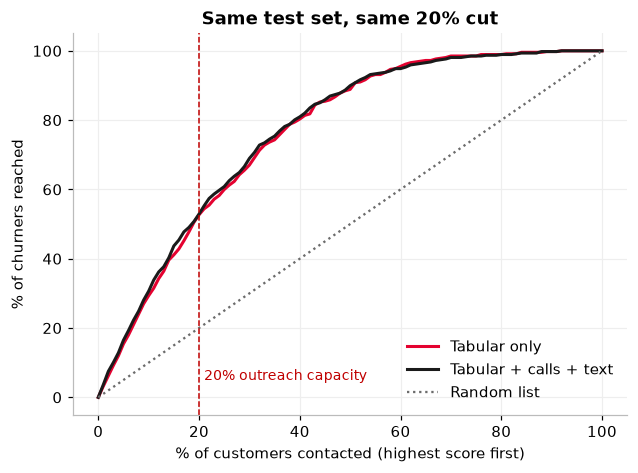

In [39]:
p_comb = scores["Tabular + call sequence + text"]
d_all = bootstrap_delta(y_te, p_tab, p_comb, "recall@20")
# Within callers, the capacity metric is the share of caller-churners that make the 20% list
top = pd.Series(p_comb, index=test_ids).rank(ascending=False) <= round(0.2 * len(test_ids))
top_tab = pd.Series(p_tab, index=test_ids).rank(ascending=False) <= round(0.2 * len(test_ids))
cal = seq.loc[test_ids, "has_called"] == 1
caller_churn = cal & (y_te == 1)
print(f"Whole test set, recall@20 change: {d_all['delta']:+.1%} (95% CI {d_all['ci_low']:+.1%} to {d_all['ci_high']:+.1%}; "
      f"better in {d_all['p_b_better']:.0%} of resamples)")
print(f"Caller churners on the list: tabular {top_tab[caller_churn].sum()} -> combined {top[caller_churn].sum()} of {caller_churn.sum()}")
print(f"Callers who stayed but are on the list: tabular {top_tab[cal & (y_te==0)].sum()} -> combined {top[cal & (y_te==0)].sum()}")
lgb_c = lgbm_model(spw).fit(Xc_tr, y_tr).predict_proba(Xc_te)[:, 1]
d_lgb = bootstrap_delta(y_te, p_lgb, lgb_c, "recall@20")
print(f"Robustness, LightGBM pair: {d_lgb['delta']:+.1%} (95% CI {d_lgb['ci_low']:+.1%} to {d_lgb['ci_high']:+.1%})")

fig, ax = plt.subplots(figsize=(6.5, 4.5))
gains_plot({"Tabular only": gain_curve(y_te, p_tab), "Tabular + calls + text": gain_curve(y_te, p_comb)}, ax=ax)
ax.set_title("Same test set, same 20% cut"); save(fig, "gains_comparison.png"); plt.show()

In [40]:
# Timing: how early do churners phone before the cancellation call?
post_all = raw_calls.assign(cid=raw_calls.customer_id.str.strip().str.upper()).merge(
    customers[["CustomerID", "churn"]], left_on="cid", right_on="CustomerID")
closers = post_all[post_all.resolution_status == "Account Closed"].groupby("cid").interaction_date.min()
earlier = post_all[post_all.cid.isin(closers.index)].assign(close=lambda d: d.cid.map(closers))
earlier = earlier[(earlier.interaction_date < earlier.close) & (earlier.interaction_date > T0)]
lead = (earlier.groupby("cid").apply(lambda g: (g.close.iloc[0] - g.interaction_date.min()).days))
print(f"{len(closers)} churners closed their account on a call; {lead.size} of them ({lead.size/len(closers):.0%}) "
      f"had called earlier inside the window, a median {lead.median():.0f} days before closing.")
print(earlier.call_type.value_counts().head(5).to_string())

254 churners closed their account on a call; 62 of them (24%) had called earlier inside the window, a median 32 days before closing.
call_type
Technical Fault           22
Complaint / Escalation    19
Plan Change Request       19
Billing Enquiry           12
Billing Dispute            7


### 5.4 Test-set for the combined model Saved to reports/test_scores_combined.csv.

In [41]:
tbl_comb = score_table(customers, test_ids, p_comb, "churn_score")
tbl_comb = tbl_comb.merge(tbl_tab[["CustomerID", "rank", "churn_score"]].rename(
    columns={"rank": "tabular_rank", "churn_score": "tabular_score"}), on="CustomerID")
tbl_comb["called_pre_T0"] = tbl_comb.CustomerID.map(seq["has_called"]).astype(int)
tbl_comb.to_csv(os.path.join(ROOT, "reports", "test_scores_combined.csv"), index=False)
with pd.option_context("display.max_rows", None, "display.max_colwidth", 45):
    print(tbl_comb[["rank", "CustomerID", "churn_score", "tabular_rank", "churn", "Churn Reason",
                    "called_pre_T0", "in_top_20pct"]].to_string(index=False, float_format=lambda v: f"{v:.3f}"))

 rank CustomerID  churn_score  tabular_rank  churn                              Churn Reason  called_pre_T0  in_top_20pct
    1 9185-TQCVP        0.998           139      1           Poor expertise of phone support              1          True
    2 2026-TGDHM        0.997           238      1                       Network reliability              1          True
    3 1658-BYGOY        0.995           532      1              Competitor made better offer              1          True
    4 2815-CPTUL        0.995           150      1                            Price too high              1          True
    5 9134-CEQMF        0.995            87      1                       Network reliability              1          True
    6 0334-GDDSO        0.994            42      1                   Service dissatisfaction              1          True
    7 3317-HRTNN        0.990           122      1 Competitor offered higher download speeds              1          True
    8 3348-CFRNX        

## 7. Microsegments for the retention

In [42]:
text_all = out_of_fold_text_risk(calls, list(X.index), y)
X_full = X.join(seq).assign(text_risk=text_all.values)
oof_all, _ = cross_validate(lambda: logistic_pipeline(X_full), X_full, y)
print("Out-of-fold, full base:", {k: round(v, 3) for k, v in at_capacity(y, oof_all).items()})

frame = customers.set_index("CustomerID").join(X_full[["protection_addons", "exit_intent_calls", "complaint_calls"]])
frame["score"] = oof_all
frame["segment"] = assign_segments(frame)
seg = segment_summary(frame)
seg.style.format({"share_of_base": "{:.1%}", "churn_rate": "{:.1%}", "lift_vs_base": "{:.2f}x",
                  "list_precision": "{:.1%}", "monthly_bill_lost": "${:,.0f}", "avg_monthly_bill": "${:.0f}",
                  "top_reason_share": "{:.0%}", "competitor_share": "{:.0%}", "support_share": "{:.0%}"})

Out-of-fold, full base: {'precision@20': np.float64(0.716), 'recall@20': np.float64(0.54), 'lift@20': np.float64(2.699), 'churners_caught': 1009, 'contacted': 1409}


,segment,customers,share_of_base,churn_rate,lift_vs_base,in_top20_list,list_precision,churners,monthly_bill_lost,avg_monthly_bill,top_reason,top_reason_share,competitor_share,support_share,action
0,Called to complain or leave,241,3.4%,53.9%,2.03x,131,81.7%,130,"$10,653",$78,Competitor,38%,38%,17%,Retention desk call-back within 48h; close the open complaint before any offer
1,"New fibre, no support add-ons",495,7.0%,73.1%,2.76x,438,76.7%,362,"$28,403",$78,Competitor,33%,33%,22%,Month-2 onboarding call; 3 months of tech support and security free
2,"New fibre, with add-ons",380,5.4%,64.2%,2.42x,293,70.0%,244,"$21,606",$87,Competitor,37%,37%,18%,Move to a 12-month contract with a first-year discount
3,"Established fibre, no contract",1137,16.1%,41.2%,1.55x,324,68.5%,468,"$42,716",$91,Competitor,32%,32%,19%,12-month price lock in exchange for a contract
4,"New DSL, no contract",676,9.6%,41.9%,1.58x,212,62.3%,283,"$12,909",$48,Competitor,33%,33%,17%,Fibre upgrade offered on a 12-month contract
5,Other month-to-month,1024,14.5%,18.2%,0.68x,3,66.7%,186,"$6,393",$37,Competitor,30%,30%,21%,No call; email contract offer
6,On 1- or 2-year contract,3090,43.9%,6.3%,0.24x,8,62.5%,196,"$16,452",$62,Competitor,33%,33%,20%,No outreach before contract end


In [43]:
# Reason mix by segment (churners only): which lever fits which segment
mix = (frame[frame.churn == 1].assign(reason=lambda d: d["Churn Reason"].map(REASON_GROUP))
          .pipe(lambda d: pd.crosstab(d.segment, d.reason, normalize="index"))
          .reindex(seg.segment))
display(mix.style.format("{:.0%}").background_gradient(cmap="Reds", axis=None))
# Tenure and bill inside the list
lst = frame[frame.score.rank(ascending=False, method="first") <= round(0.2 * len(frame))]
print(f"List: {len(lst)} customers, {lst.churn.mean():.1%} would churn, avg bill ${lst['Monthly Charges'].mean():.0f}; "
      f"{(lst.Contract=='Month-to-month').mean():.0%} month-to-month, {(lst['Internet Service']=='Fiber optic').mean():.0%} fibre")

reason,Competitor,Not saveable,Price,Product / network,Support experience,Unknown
segment,,,,,,
Called to complain or leave,38%,2%,16%,21%,17%,7%
"New fibre, no support add-ons",33%,4%,12%,21%,22%,8%
"New fibre, with add-ons",37%,3%,13%,23%,18%,6%
"Established fibre, no contract",32%,3%,14%,24%,19%,8%
"New DSL, no contract",33%,2%,12%,25%,17%,10%
Other month-to-month,30%,3%,11%,24%,21%,11%
On 1- or 2-year contract,33%,5%,14%,21%,20%,7%


List: 1409 customers, 71.6% would churn, avg bill $79; 99% month-to-month, 83% fibre


In [44]:
# Persist the numbers used by the ExCom deck
DECK["split"] = {"train": len(train_ids), "test": len(test_ids), "test_churners": int(y_te.sum()), "list_test": round(0.2*len(test_ids))}
DECK["cv"] = cv.round(4).to_dict(orient="index")
DECK["test"] = {k: {kk: float(vv) for kk, vv in v.items()} for k, v in test_metrics.to_dict(orient="index").items()}
DECK["recall_ci"] = [float(lo), float(hi)]
DECK["capacity_curve"] = caps.round(4).to_dict(orient="records")
DECK["deciles"] = dec_tab.reset_index().astype({"decile": int}).round(4).to_dict(orient="records")
DECK["gains"] = {"tabular": gain_curve(y_te, p_tab, 20).round(4).to_dict(orient="list"),
                 "combined": gain_curve(y_te, p_comb, 20).round(4).to_dict(orient="list")}
DECK["reach_by_reason"] = reach.reset_index().round(4).to_dict(orient="records")
DECK["calls"] = {"raw_calls": len(raw_calls), "audit": call_audit, "usable_calls": len(calls),
                 "callers": int(calls.customer_id.nunique()), "post_t0_termination": int(len(term)),
                 "post_t0_closed": int((term.resolution_status == 'Account Closed').sum()),
                 "caller_churn": float(cust_rate), "closers": int(len(closers)), "early_callers": int(lead.size),
                 "lead_median_days": float(lead.median())}
DECK["comparison"] = comparison.round(4).to_dict(orient="index")
DECK["delta"] = {"lr": {k: float(v) for k, v in d_all.items()}, "lgb": {k: float(v) for k, v in d_lgb.items()},
                 "caller_churners": int(caller_churn.sum()), "caller_churners_tab": int(top_tab[caller_churn].sum()),
                 "caller_churners_comb": int(top[caller_churn].sum()), "test_callers": int(callers_te.sum())}
DECK["segments"] = seg.round(4).to_dict(orient="records")
DECK["segment_mix"] = mix.round(4).fillna(0).to_dict(orient="index")
DECK["list_full"] = {"n": len(lst), "precision": float(lst.churn.mean()), "avg_bill": float(lst["Monthly Charges"].mean()),
                     "m2m": float((lst.Contract == 'Month-to-month').mean()), "fibre": float((lst['Internet Service'] == 'Fiber optic').mean()),
                     **{k: float(v) for k, v in at_capacity(y, oof_all).items()}}
with open(os.path.join(ROOT, "reports", "deck_data.json"), "w") as f:
    json.dump(DECK, f, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
print("saved reports/deck_data.json")

saved reports/deck_data.json
